# Лабораторная работа №5
## Графы

**Выполнил:** Улискин Даниил Евгеньевич  
**Группа:** ФИТ-241  
**Вариант:** 4

## Общая реализация графа

Во всех заданиях используется собственный класс `Graph` из лекционного подхода. Граф хранит вершины, а каждая вершина хранит исходящие рёбра и их веса.

In [1]:
from collections import deque
import heapq
import math


class Vertex:
    """Вершина ориентированного графа."""

    def __init__(self, key):
        self.key = key
        self.connected_to = {}

    def add_neighbor(self, neighbor, weight=0):
        self.connected_to[neighbor] = weight

    def get_connections(self):
        return self.connected_to.keys()

    def get_weight(self, neighbor):
        return self.connected_to[neighbor]

    def __str__(self):
        neighbors = [vertex.key for vertex in self.connected_to]
        return f'{self.key} -> {neighbors}'


class Graph:
    """Ориентированный граф на основе словаря вершин."""

    def __init__(self):
        self.vertices = {}

    def add_vertex(self, key):
        if key not in self.vertices:
            self.vertices[key] = Vertex(key)
        return self.vertices[key]

    def add_edge(self, source, target, weight=0):
        source_vertex = self.add_vertex(source)
        target_vertex = self.add_vertex(target)
        source_vertex.add_neighbor(target_vertex, weight)

    def get_vertex(self, key):
        return self.vertices.get(key)

    def __contains__(self, key):
        return key in self.vertices

    def __iter__(self):
        return iter(self.vertices.values())

    def __len__(self):
        return len(self.vertices)

    def to_adjacency_list(self, include_weights=False):
        result = {}
        for vertex in self:
            if include_weights:
                result[vertex.key] = [
                    (neighbor.key, vertex.get_weight(neighbor))
                    for neighbor in vertex.get_connections()
                ]
            else:
                result[vertex.key] = [
                    neighbor.key
                    for neighbor in vertex.get_connections()
                ]
        return result


def check(description, condition):
    """Печатает результат проверки и останавливается при ошибке."""
    if not condition:
        raise AssertionError(description)
    print(f'{description:<65} OK')

## Задание №1 (2 балла)

В примере алгоритма поиска в ширину из лекции структура данных «граф» представлена словарём. Переделайте этот пример, заменив словарь реализацией класса `Graph` из лекционных материалов.

В исходном примере BFS ищет среди знакомых человека-продавца: продавцом считается человек, чьё имя начинается с буквы `a`.

In [2]:
def person_is_seller(name):
    """Условие из исходного примера по ссылке."""
    return name[0] == 'a'


def search_seller(graph, start):
    """BFS из исходного примера, переделанный для класса Graph."""
    if start not in graph:
        raise KeyError(f'Вершина {start!r} отсутствует в графе')

    start_vertex = graph.get_vertex(start)
    search_queue = deque(
        neighbor.key
        for neighbor in start_vertex.get_connections()
    )
    searched = set()
    visit_order = []

    while search_queue:
        person = search_queue.popleft()

        if person not in searched:
            visit_order.append(person)

            if person_is_seller(person):
                return person, visit_order

            person_vertex = graph.get_vertex(person)
            search_queue.extend(
                neighbor.key
                for neighbor in person_vertex.get_connections()
            )
            searched.add(person)

    return None, visit_order


# Тот же граф людей, что и в файле 2.py по ссылке из задания.
seller_graph = Graph()
for person in [
    'you',
    'alice',
    'bob',
    'claire',
    'anuj',
    'peggy',
    'thom',
    'jonny',
]:
    seller_graph.add_vertex(person)

for source, target in [
    ('you', 'alice'),
    ('you', 'bob'),
    ('you', 'claire'),
    ('bob', 'anuj'),
    ('bob', 'peggy'),
    ('alice', 'peggy'),
    ('claire', 'thom'),
    ('claire', 'jonny'),
]:
    seller_graph.add_edge(source, target)

seller, visit_order = search_seller(seller_graph, 'you')

print('Граф из исходного примера:')
print(seller_graph.to_adjacency_list())
print('Порядок проверки BFS:', ' -> '.join(visit_order))
print('Найденный продавец:', seller)

check(
    'Вместо словаря используется объект класса Graph',
    isinstance(seller_graph, Graph),
)
check(
    'BFS первым проверяет непосредственных знакомых',
    visit_order[0] == 'alice',
)
check(
    'Продавцом найден человек с именем на букву a',
    seller == 'alice' and person_is_seller(seller),
)

seller_from_bob, order_from_bob = search_seller(
    seller_graph,
    'bob',
)
check(
    'Поиск из bob находит anuj на следующем уровне',
    seller_from_bob == 'anuj'
    and order_from_bob == ['anuj'],
)

no_seller, checked_people = search_seller(
    seller_graph,
    'claire',
)
check(
    'Если продавца нет, функция возвращает None',
    no_seller is None
    and checked_people == ['thom', 'jonny'],
)

Граф из исходного примера:
{'you': ['alice', 'bob', 'claire'], 'alice': ['peggy'], 'bob': ['anuj', 'peggy'], 'claire': ['thom', 'jonny'], 'anuj': [], 'peggy': [], 'thom': [], 'jonny': []}
Порядок проверки BFS: alice
Найденный продавец: alice
Вместо словаря используется объект класса Graph                   OK
BFS первым проверяет непосредственных знакомых                    OK
Продавцом найден человек с именем на букву a                      OK
Поиск из bob находит anuj на следующем уровне                     OK
Если продавца нет, функция возвращает None                        OK


## Задание №2 (2 балла)

Реализуйте программу, которая по заданному в виде списка смежности графу строит **обращённый граф**, также представленный списком смежности. Обращённый граф получается изменением направления всех рёбер исходного графа. Используйте класс `Graph`.

In [3]:
def graph_from_adjacency_list(adjacency_list):
    """Создаёт объект Graph из словаря со списками соседей."""
    graph = Graph()

    for vertex_key in adjacency_list:
        graph.add_vertex(vertex_key)

    for source, targets in adjacency_list.items():
        for target in targets:
            graph.add_edge(source, target)

    return graph


def reverse_graph(graph):
    """Создаёт новый граф с обратным направлением всех рёбер."""
    reversed_graph = Graph()

    for vertex in graph:
        reversed_graph.add_vertex(vertex.key)

    for vertex in graph:
        for neighbor in vertex.get_connections():
            reversed_graph.add_edge(
                neighbor.key,
                vertex.key,
                vertex.get_weight(neighbor),
            )

    return reversed_graph


initial_adjacency = {
    0: [1, 2],
    1: [3],
    2: [1],
    3: [],
}

initial_graph = graph_from_adjacency_list(initial_adjacency)
reversed_graph = reverse_graph(initial_graph)
reversed_adjacency = reversed_graph.to_adjacency_list()

print('Первоначальный граф:', initial_graph.to_adjacency_list())
print('Обращённый граф:    ', reversed_adjacency)

expected_reversed = {
    0: [],
    1: [0, 2],
    2: [0],
    3: [1],
}

check(
    'Все направления рёбер изменены на противоположные',
    reversed_adjacency == expected_reversed,
)
check(
    'Количество вершин не изменилось',
    len(initial_graph) == len(reversed_graph),
)

Первоначальный граф: {0: [1, 2], 1: [3], 2: [1], 3: []}
Обращённый граф:     {0: [], 1: [0, 2], 2: [0], 3: [1]}
Все направления рёбер изменены на противоположные                 OK
Количество вершин не изменилось                                   OK


## Задание №3 (4 балла)

Процесс приготовления блинов представлен ориентированным графом зависимостей. Напишите программу, которая при помощи поиска в глубину (DFS) выполняет топологическую сортировку и выдаёт корректную последовательность шагов.

Используйте класс `Graph`.

In [4]:
def topological_sort(graph):
    """Топологическая сортировка ориентированного графа с помощью DFS."""
    state = {vertex.key: 0 for vertex in graph}
    # 0 — не посещена, 1 — обрабатывается, 2 — обработана
    result = []

    def dfs(vertex):
        if state[vertex.key] == 1:
            raise ValueError('В графе найден цикл')
        if state[vertex.key] == 2:
            return

        state[vertex.key] = 1
        for neighbor in vertex.get_connections():
            dfs(neighbor)
        state[vertex.key] = 2
        result.append(vertex.key)

    for vertex in graph:
        if state[vertex.key] == 0:
            dfs(vertex)

    result.reverse()
    return result


pancake_graph = Graph()
pancake_steps = [
    'Добавить яйцо',
    'Добавить блинную смесь',
    'Добавить растительное масло',
    'Добавить молоко',
    'Смешать ингредиенты',
    'Разогреть сковороду',
    'Налить порцию смеси',
    'Перевернуть блин',
    'Нагреть сироп',
    'Полить сиропом и подать',
]
for step in pancake_steps:
    pancake_graph.add_vertex(step)

pancake_dependencies = [
    ('Добавить яйцо', 'Смешать ингредиенты'),
    ('Добавить блинную смесь', 'Смешать ингредиенты'),
    ('Добавить растительное масло', 'Смешать ингредиенты'),
    ('Добавить молоко', 'Смешать ингредиенты'),
    ('Смешать ингредиенты', 'Налить порцию смеси'),
    ('Разогреть сковороду', 'Налить порцию смеси'),
    ('Налить порцию смеси', 'Перевернуть блин'),
    ('Смешать ингредиенты', 'Нагреть сироп'),
    ('Перевернуть блин', 'Полить сиропом и подать'),
    ('Нагреть сироп', 'Полить сиропом и подать'),
]
for before, after in pancake_dependencies:
    pancake_graph.add_edge(before, after)

cooking_order = topological_sort(pancake_graph)

print('Корректная последовательность приготовления:')
for number, step in enumerate(cooking_order, start=1):
    print(f'{number:2}. {step}')

position = {
    step: index
    for index, step in enumerate(cooking_order)
}
check(
    'Все шаги присутствуют ровно один раз',
    len(cooking_order) == len(pancake_steps)
    and set(cooking_order) == set(pancake_steps),
)
check(
    'Каждая зависимость выполняется в правильном порядке',
    all(
        position[before] < position[after]
        for before, after in pancake_dependencies
    ),
)

cyclic_graph = Graph()
cyclic_graph.add_edge('A', 'B')
cyclic_graph.add_edge('B', 'A')
try:
    topological_sort(cyclic_graph)
except ValueError:
    print('Проверка цикла: цикл правильно обнаружен                  OK')
else:
    raise AssertionError('Алгоритм должен обнаруживать цикл')

Корректная последовательность приготовления:
 1. Разогреть сковороду
 2. Добавить молоко
 3. Добавить растительное масло
 4. Добавить блинную смесь
 5. Добавить яйцо
 6. Смешать ингредиенты
 7. Нагреть сироп
 8. Налить порцию смеси
 9. Перевернуть блин
10. Полить сиропом и подать
Все шаги присутствуют ровно один раз                              OK
Каждая зависимость выполняется в правильном порядке               OK
Проверка цикла: цикл правильно обнаружен                  OK


## Задание №4 (5 баллов). Вариант 4

Имеется список городов и набор **однонаправленных** автобусных маршрутов. Пользователь вводит два города. Программа должна определить минимальный по количеству километров путь от первого города до второго либо сообщить, что пути нет. Нужно вывести расстояние и сам путь.

Для решения используется алгоритм Дейкстры и класс `Graph`.

### Города варианта 4

Мариинск, Яя, Яшкино, Юрга, Анжеро-Судженск, Кемерово, Томск.

### Маршруты и использованные автомобильные расстояния

| Направленный маршрут | Расстояние |
|---|---:|
| Мариинск → Яя | 107 км |
| Мариинск → Яшкино | 225 км |
| Мариинск → Юрга | 278 км |
| Мариинск → Анжеро-Судженск | 146 км |
| Яя → Кемерово | 131 км |
| Яшкино → Яя | 125 км |
| Яшкино → Томск | 150 км |
| Юрга → Яшкино | 47 км |
| Юрга → Томск | 110 км |
| Юрга → Анжеро-Судженск | 135 км |
| Томск → Кемерово | 224 км |

Расстояния округлены до километров по данным сервисов [Автодиспетчер](https://www.avtodispetcher.ru/distance/)

Кратчайший путь: Мариинск → Яя → Кемерово
Расстояние: 238 км
Кратчайший путь проходит через Яю                                 OK
Минимальное расстояние равно 238 км                               OK
При отсутствии обратных маршрутов возвращается пустой путь        OK


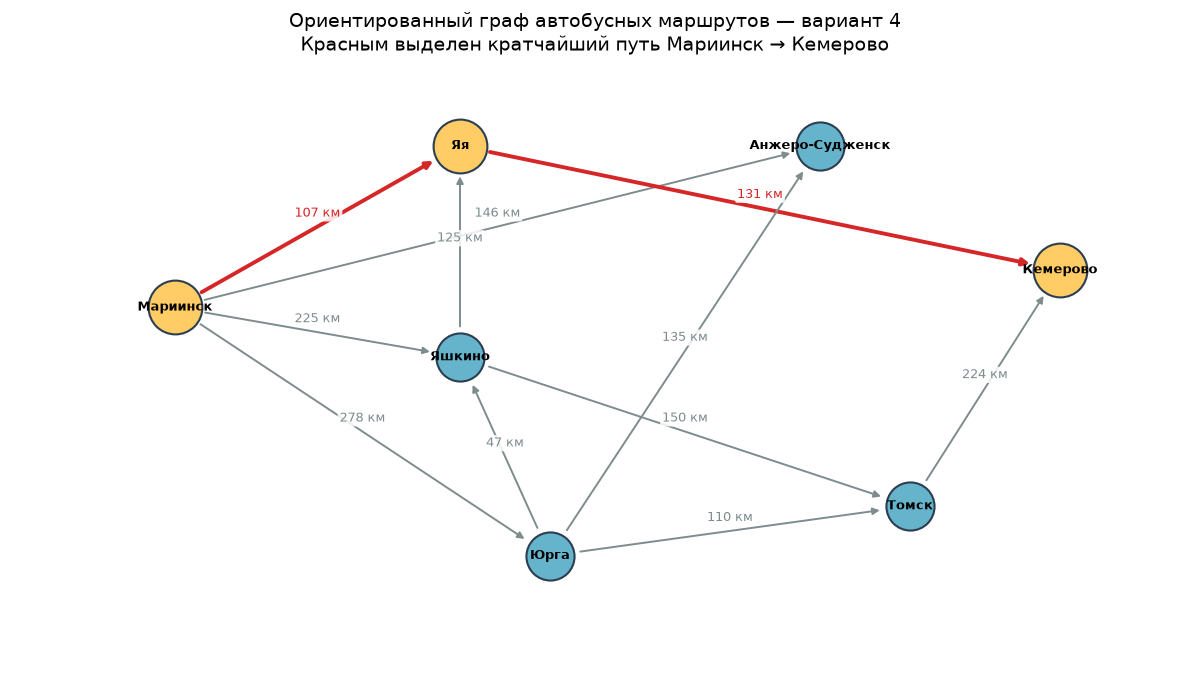

In [5]:
import matplotlib.pyplot as plt


def dijkstra(graph, start, finish):
    """Возвращает минимальное расстояние и путь между двумя вершинами."""
    if start not in graph:
        raise KeyError(f'Неизвестный начальный город: {start}')
    if finish not in graph:
        raise KeyError(f'Неизвестный конечный город: {finish}')

    distances = {
        vertex.key: math.inf
        for vertex in graph
    }
    previous = {}
    distances[start] = 0
    queue = [(0, start)]

    while queue:
        current_distance, current_key = heapq.heappop(queue)

        if current_distance != distances[current_key]:
            continue
        if current_key == finish:
            break

        current_vertex = graph.get_vertex(current_key)
        for neighbor in current_vertex.get_connections():
            weight = current_vertex.get_weight(neighbor)
            if weight < 0:
                raise ValueError('Алгоритм Дейкстры не допускает отрицательные веса')

            new_distance = current_distance + weight
            if new_distance < distances[neighbor.key]:
                distances[neighbor.key] = new_distance
                previous[neighbor.key] = current_key
                heapq.heappush(
                    queue,
                    (new_distance, neighbor.key),
                )

    if math.isinf(distances[finish]):
        return math.inf, []

    path = []
    current = finish
    while current != start:
        path.append(current)
        current = previous[current]
    path.append(start)
    path.reverse()

    return distances[finish], path


def print_shortest_route(graph, start, finish):
    """Печатает результат поиска маршрута."""
    distance, path = dijkstra(graph, start, finish)
    if not path:
        print(f'Пути из города {start} в город {finish} нет.')
    else:
        print(f'Кратчайший путь: {" → ".join(path)}')
        print(f'Расстояние: {distance} км')
    return distance, path


def ask_cities_and_find_route(graph):
    """Интерактивный ввод двух городов для ручной проверки."""
    print('Доступные города:', ', '.join(graph.vertices))
    start = input('Начальный город: ').strip()
    finish = input('Конечный город: ').strip()
    return print_shortest_route(graph, start, finish)


city_graph = Graph()
cities = [
    'Мариинск',
    'Яя',
    'Яшкино',
    'Юрга',
    'Анжеро-Судженск',
    'Кемерово',
    'Томск',
]
for city in cities:
    city_graph.add_vertex(city)

city_routes = [
    ('Мариинск', 'Яя', 107),
    ('Мариинск', 'Яшкино', 225),
    ('Мариинск', 'Юрга', 278),
    ('Мариинск', 'Анжеро-Судженск', 146),
    ('Яя', 'Кемерово', 131),
    ('Яшкино', 'Яя', 125),
    ('Яшкино', 'Томск', 150),
    ('Юрга', 'Яшкино', 47),
    ('Юрга', 'Томск', 110),
    ('Юрга', 'Анжеро-Судженск', 135),
    ('Томск', 'Кемерово', 224),
]
for source, target, distance in city_routes:
    city_graph.add_edge(source, target, distance)

start_city = 'Мариинск'
finish_city = 'Кемерово'
shortest_distance, shortest_path = print_shortest_route(
    city_graph,
    start_city,
    finish_city,
)

check(
    'Кратчайший путь проходит через Яю',
    shortest_path == ['Мариинск', 'Яя', 'Кемерово'],
)
check(
    'Минимальное расстояние равно 238 км',
    shortest_distance == 238,
)

missing_distance, missing_path = dijkstra(
    city_graph,
    'Кемерово',
    'Мариинск',
)
check(
    'При отсутствии обратных маршрутов возвращается пустой путь',
    math.isinf(missing_distance) and missing_path == [],
)


def draw_city_graph(graph, positions, highlighted_path=None):
    """Рисует ориентированный взвешенный граф городов."""
    highlighted_edges = set()
    if highlighted_path:
        highlighted_edges = set(
            zip(highlighted_path, highlighted_path[1:])
        )

    figure, axis = plt.subplots(figsize=(12, 7))

    for vertex in graph:
        x1, y1 = positions[vertex.key]
        for neighbor in vertex.get_connections():
            x2, y2 = positions[neighbor.key]
            edge = (vertex.key, neighbor.key)
            highlighted = edge in highlighted_edges
            color = '#d62728' if highlighted else '#7f8c8d'
            width = 2.8 if highlighted else 1.4

            axis.annotate(
                '',
                xy=(x2, y2),
                xytext=(x1, y1),
                arrowprops={
                    'arrowstyle': '-|>',
                    'color': color,
                    'lw': width,
                    'shrinkA': 22,
                    'shrinkB': 22,
                },
                zorder=1,
            )

            middle_x = (x1 + x2) / 2
            middle_y = (y1 + y2) / 2
            axis.text(
                middle_x,
                middle_y + 0.08,
                f'{vertex.get_weight(neighbor)} км',
                fontsize=9,
                color=color,
                bbox={
                    'boxstyle': 'round,pad=0.15',
                    'facecolor': 'white',
                    'edgecolor': 'none',
                    'alpha': 0.85,
                },
                ha='center',
                zorder=3,
            )

    for city, (x, y) in positions.items():
        in_path = city in (highlighted_path or [])
        axis.scatter(
            x,
            y,
            s=1500 if in_path else 1200,
            color='#ffcc66' if in_path else '#66b3cc',
            edgecolor='#2c3e50',
            linewidth=1.5,
            zorder=4,
        )
        axis.text(
            x,
            y,
            city,
            ha='center',
            va='center',
            fontsize=9,
            fontweight='bold',
            zorder=5,
        )

    axis.set_title(
        'Ориентированный граф автобусных маршрутов — вариант 4\n'
        'Красным выделен кратчайший путь Мариинск → Кемерово',
        fontsize=14,
    )
    axis.set_xlim(-0.8, 7.0)
    axis.set_ylim(-0.8, 4.2)
    axis.axis('off')
    plt.tight_layout()
    plt.show()


city_positions = {
    'Мариинск': (0.3, 2.2),
    'Яя': (2.2, 3.5),
    'Яшкино': (2.2, 1.8),
    'Юрга': (2.8, 0.2),
    'Анжеро-Судженск': (4.6, 3.5),
    'Кемерово': (6.2, 2.5),
    'Томск': (5.2, 0.6),
}

draw_city_graph(
    city_graph,
    city_positions,
    highlighted_path=shortest_path,
)

# Для ручного ввода раскомментируйте следующую строку:
# ask_cities_and_find_route(city_graph)

## Вывод

В лабораторной работе реализованы:

- собственные классы `Graph` и `Vertex`;
- поиск в ширину BFS;
- построение обращённого ориентированного графа;
- топологическая сортировка при помощи DFS с обнаружением циклов;
- поиск кратчайшего пути алгоритмом Дейкстры;
- визуализация ориентированного взвешенного графа варианта 4.

Все алгоритмы снабжены наглядными проверками.